# Шаг 3. Биграммы как нейросеть

В шаге 2 вероятности мы **посчитали**. Теперь пусть их **выучит** нейросеть — тем же способом, что в сессиях 3–4:
предсказание → loss → градиент → маленький шаг весов.

Сеть очень простая — **таблица весов** `nn.Embedding(V, V)`: для каждого символа хранится строка из V чисел — «сырые оценки» (*logits*)
следующего символа. Softmax превращает их в вероятности.

`Embedding` — это то же самое, что `Linear(V, V)`, применённый к вектору **one-hot** (одна единица на месте номера символа, остальное нули),
только быстрее: вместо умножения на кучу нулей просто берётся нужная строка таблицы.
Embedding будет первым слоем и в GPT (шаг 6).

**Структура примера (алгоритм):**
1. Создаём таблицу весов и смотрим на one-hot.
2. Разбираем по косточкам один шаг обучения на одной паре букв.
3. Обучаем 300 шагов на всех парах букв сразу.
4. Сравниваем loss и вероятности с подсчётами из шага 2.
5. Придумываем имена и сравниваем две таблицы вероятностей на картинке.

In [ ]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session01–session05 и dataset).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session05")  # здесь лежит common.py и сохраняются результаты
    sys.path.insert(0, os.getcwd())

## Общий модуль `common.py`

Во всех примерах сессии используется модуль `common.py` из этой же папки:

| Имя | Что делает |
|-----|------------|
| `load_names()`, `load_text()` | русские имена из `names.txt` и «Евгений Онегин» (главы 1–8) из `onegin.txt` |
| `CharTokenizer(text)` | словарь символов: `encode` — строка → номера, `decode` — номера → строка, `vocab_size` — размер словаря |
| `name_tokenizer`, `bigram_pairs`, `bigram_counts` | словарь для имён (точка `.` — начало/конец имени), пары «буква → следующая», таблица подсчётов |
| `sample_name(probs, tok)` | придумать имя по таблице вероятностей |
| `apply_temperature(logits, T)` | вероятности из «сырых оценок» с температурой T |
| `MiniGPT`, `Block`, `SelfAttention` | маленький трансформер по символам |
| `save_gpt`, `load_gpt` | сохранить / загрузить GPT вместе со словарём |
| `load_session04()` | модуль `common.py` из сессии 4 (кошки и собаки, `SimpleCNN`) — для бонуса |
| `show()` | показать графики matplotlib |

> Запускайте примеры из папки `session05`, иначе `import common` не найдёт модуль.
> Библиотеки: `pip install -r requirements.txt`. Тексты лежат в этой же папке, интернет не нужен.

## 1. Таблица весов и one-hot

Пока веса случайные, поэтому сырые оценки — случайные числа, и вероятности после softmax — тоже случайные.
Но они уже **в сумме дают 1**: softmax всегда превращает любые числа в распределение вероятностей.

In [1]:
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F

from common import BOUNDARY, bigram_counts, bigram_pairs, load_names, name_tokenizer, sample_name, show

torch.manual_seed(0)
names = load_names()
tok = name_tokenizer(names)
xs, ys = bigram_pairs(names, tok)
V = tok.vocab_size

# Embedding(V, V): для каждого символа — строка из V чисел, «сырые оценки» (logits) следующего символа.
# Это то же самое, что Linear(V, V) от вектора one-hot, только быстрее.
model = nn.Embedding(V, V)
print("Весов в сети:", sum(p.numel() for p in model.parameters()), f"= {V} × {V}")

x = F.one_hot(xs[:3], V).float()
print("Первые три буквы как one-hot (одна единица, остальное нули):")
print(x)
print("one-hot × таблица весов == Embedding:", torch.allclose(x @ model.weight, model(xs[:3])))

logits = model(xs[:1])
print("Сырые оценки для первой пары (сеть ещё не обучена):", logits.detach().round(decimals=2))
print("После softmax — вероятности, их сумма:", torch.softmax(logits, dim=1).sum().item())

Весов в сети: 841 = 29 × 29
Первые три буквы как one-hot (одна единица, остальное нули):
tensor([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])
one-hot × таблица весов == Embedding: True
Сырые оценки для первой пары (сеть ещё не обучена): tensor([[-1.1300, -1.1500, -0.2500, -0.4300,  0.8500,  0.6900, -0.3200, -2.1200,
          0.3200, -1.2600,  0.3500,  0.3100,  0.1200,  1.2400,  1.1200, -0.2500,
         -1.3500, -1.7000,  0.5700,  0.7900,  0.6000, -1.5600, -0.3400,  1.8500,
          0.7500, -0.5900, -0.1700,  0.1800,  1.3900]])
После softmax — вероятности, их сумма: 1.0


## 2. Один шаг обучения под лупой

Возьмём отдельную табличку `demo` и будем учить её только одной паре: «после „а“ имя заканчивается».
Используем простой оптимизатор `SGD` — он делает ровно `вес = вес − lr × градиент`.

Что видно в выводе:
- с каждым шагом вероятность правильного ответа растёт, а loss падает;
- градиент строки «а» равен **вероятности минус правильный ответ**: у правильного символа он отрицательный (оценку надо увеличить),
  у остальных — положительный и тем больше, чем увереннее сеть ошибалась. Это красивое свойство пары softmax + cross-entropy;
- меняется только **одна** строка таблицы — строка буквы «а». Остальные строки на этой паре не участвовали в ответе, их градиент равен 0.

In [2]:
# Что делает один шаг обучения? Учим отдельную табличку одной паре «а → .» (имя кончается на «а»)
demo = nn.Embedding(V, V)
a, b = tok.stoi["а"], tok.stoi[BOUNDARY]
demo_opt = torch.optim.SGD(demo.parameters(), lr=1.0)
for i in range(4):
    loss = F.cross_entropy(demo(torch.tensor([a])), torch.tensor([b]))
    demo_opt.zero_grad()
    loss.backward()
    p = torch.softmax(demo.weight[a], dim=0)
    print(f"Шаг {i}: P(«.» после «а») = {p[b]:.3f}, loss = {loss.item():.3f}")
    demo_opt.step()
grad = demo.weight.grad
print("Градиент строки «а» = вероятности − правильный ответ (one-hot):",
      torch.allclose(grad[a], p.detach() - F.one_hot(torch.tensor(b), V)))
print("Строк таблицы, которые изменились бы на этом шаге:", int((grad.abs().sum(1) > 0).sum()), "из", V)

Шаг 0: P(«.» после «а») = 0.014, loss = 4.256
Шаг 1: P(«.» после «а») = 0.040, loss = 3.223
Шаг 2: P(«.» после «а») = 0.104, loss = 2.266
Шаг 3: P(«.» после «а») = 0.231, loss = 1.465
Градиент строки «а» = вероятности − правильный ответ (one-hot): True
Строк таблицы, которые изменились бы на этом шаге: 1 из 29


## 3. Обучение

Пар всего ~1400, поэтому подаём их **все сразу**, без мини-батчей. `F.cross_entropy` сама делает softmax и считает штраф.
Каждый шаг — это сразу ~1400 маленьких «толчков», как в пункте 2, сложенных вместе.
Оптимизатор `Adam` — более хитрый родственник `SGD`, он подбирает размер шага для каждого веса сам.

In [3]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)
history = []
for step in range(301):
    loss = F.cross_entropy(model(xs), ys)   # сразу все пары, без мини-батчей: их всего ~1400
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    history.append(loss.item())
    if step % 50 == 0:
        print(f"Шаг {step:3d}: loss = {loss.item():.3f}")

Шаг   0: loss = 3.826
Шаг  50: loss = 2.160
Шаг 100: loss = 2.142
Шаг 150: loss = 2.138
Шаг 200: loss = 2.136
Шаг 250: loss = 2.135
Шаг 300: loss = 2.135


## 4. Сравнение с подсчётами

Loss нейросети получается **почти таким же**, как у подсчётов, а вероятности после «а» совпадают до сотых.
Нейросеть сама «додумалась» до статистики пар букв — хотя мы ей ничего не считали, только показывали примеры.
Чуть меньший loss у сети — потому что у подсчётов есть сглаживание `+ 0.1`, а сеть подстраивается точно под эти имена.

In [4]:
counts = bigram_counts(names, tok)
probs_counts = (counts + 0.1) / (counts + 0.1).sum(dim=1, keepdim=True)
loss_counts = -probs_counts[xs, ys].log().mean().item()
print(f"Loss нейросети: {history[-1]:.3f}, loss подсчётов из шага 2: {loss_counts:.3f}")

probs_net = torch.softmax(model.weight.detach(), dim=1)
print("После «а»: подсчёты → нейросеть")
for i in probs_counts[a].argsort(descending=True)[:5].tolist():
    print(f"  «{tok.itos[i]}»: {probs_counts[a, i]:.3f} → {probs_net[a, i]:.3f}")

Loss нейросети: 2.135, loss подсчётов из шага 2: 2.168
После «а»: подсчёты → нейросеть
  «.»: 0.348 → 0.352
  «н»: 0.130 → 0.131
  «р»: 0.121 → 0.122
  «в»: 0.088 → 0.089
  «л»: 0.070 → 0.070


## 5. Имена и таблицы

Таблицы вероятностей почти одинаковые на вид, имена — того же «качества».

Зачем тогда нейросеть, если можно посчитать? Подсчёты работают, только пока таблица маленькая.
Если смотреть на 10 предыдущих букв, клеток будет 29¹⁰ — столько текста не существует.
А нейросеть можно сделать умнее, не раздувая таблицу: добавить слои и внимание. Это и есть путь к GPT.

Имена от нейросети:
а, ана, офья, кодмидригдий, юлёд, вя, зага, юбогерагарока, верикия, саролланинаиянавег, вегерей, ия, я, алас, веваналюлиилья, дминтакслил, влий, я, малараваг, ветия


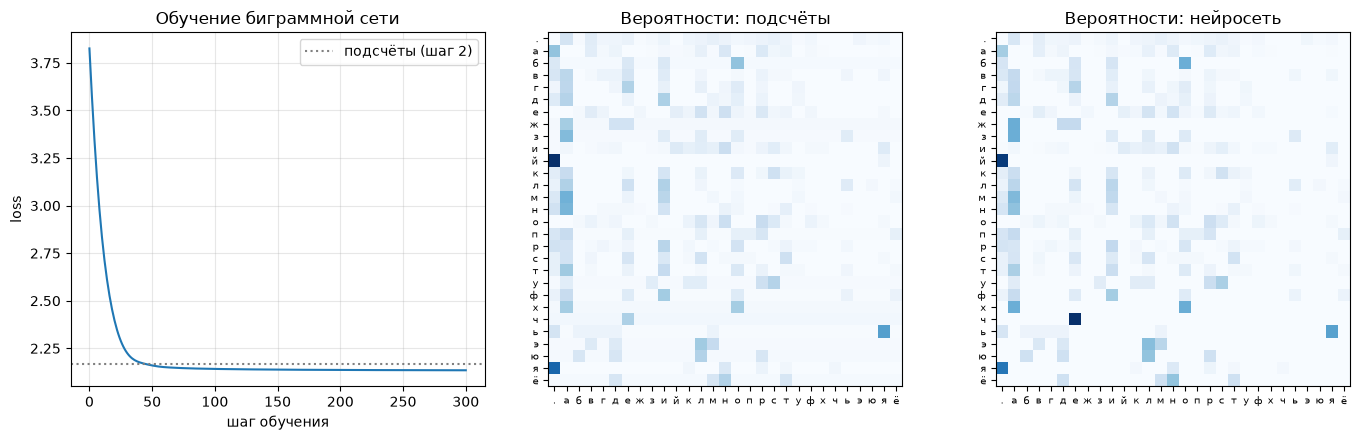

In [5]:
g = torch.Generator().manual_seed(1)
print("Имена от нейросети:")
print(", ".join(sample_name(probs_net, tok, g) for _ in range(20)))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
axes[0].plot(history)
axes[0].axhline(loss_counts, color="gray", linestyle=":", label="подсчёты (шаг 2)")
axes[0].set_xlabel("шаг обучения")
axes[0].set_ylabel("loss")
axes[0].set_title("Обучение биграммной сети")
axes[0].legend()
axes[0].grid(alpha=0.3)
for ax, p, title in [(axes[1], probs_counts, "Вероятности: подсчёты"), (axes[2], probs_net, "Вероятности: нейросеть")]:
    ax.imshow(p, cmap="Blues")
    ax.set_xticks(range(V), tok.chars, fontsize=7)
    ax.set_yticks(range(V), tok.chars, fontsize=7)
    ax.set_title(title)
plt.tight_layout()
plt.savefig("bigram_neural.png", dpi=100)
show()

## Попробуйте сами

1. Поменяйте скорость обучения `lr` на 0.01 и 1.0. Как меняется кривая loss?
2. В пункте 2 сделайте 20 шагов вместо 4. До какой вероятности дорастёт P(«.» после «а»)? Хорошо ли это для настоящих имён?
3. Обучите 2000 шагов. Становится ли loss меньше, чем у подсчётов? Почему так может быть (вспомните сглаживание)?
4. Замените `nn.Embedding(V, V)` на `nn.Sequential(nn.Embedding(V, 16), nn.Linear(16, V))`. Сколько стало весов? Как изменился loss?